# 08b — Multi-Agent: Rechnungen prüfen und verbuchen

**Lernziel.** Du baust ein System aus drei Agenten mit getrennten Rollen: Einer liest
eine Rechnung aus, ein zweiter mit einem anderen Modell prüft nach dem Vier-Augen-Prinzip,
ein dritter wählt das Konto. Verbucht und abgelegt wird danach mit festem Code.
Der erste Agent liest das PDF wie ein Mensch, als Dokument; geprüft wird gegen den Text in der Datei.

**Dauer.** Rund 25 Minuten.

**Voraussetzungen.** Notebook 05 (Knoten, Kanten, strukturierte Ausgabe). Die Rechnungen
in `data_invoices/`.

**Empfohlen:** lokal ausführen, zum Beispiel in PyCharm.

---

Ein neuer Fall, unabhängig vom SWISS-Agenten: die Kreditorenbuchhaltung. Es kommen
Rechnungen als PDF herein, und am Ende soll jede verbucht und abgelegt sein.

## Setup

Dieselben Zellen wie in Woche 8, dazu ein zweites Modell für die Prüfung.

In [1]:
%pip install -q -r requirements.txt

In [2]:
LLM_MODEL = "gpt-5.6-luna"
LLM_BASE_URL = "https://litellm.engines.aisl.science/v1"
REVIEW_MODEL = "azure_ai/mistral-large-3"  # prüft die Extraktion, anderer Anbieter

# Weitere Modelle auf demselben Proxy:
#   "gpt-5.4-mini-new"

In [3]:
import os
from dotenv import load_dotenv
from getpass import getpass

# load_dotenv liest die .env, überschreibt aber nichts, was schon gesetzt ist.
load_dotenv()

if not os.environ.get("LITELLM_API_KEY"):
    os.environ["LITELLM_API_KEY"] = getpass("LITELLM_API_KEY: ")

In [4]:
# vor dem ersten Modellaufruf setzen, sonst greift das Tracing nicht
if os.environ.get("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "genai_rechnungen_cw8"
    print("Tracing läuft. Projekt:", os.environ["LANGSMITH_PROJECT"])
else:
    os.environ["LANGSMITH_TRACING"] = "false"
    print("Kein LANGSMITH_API_KEY gefunden — weiter ohne Tracing.")

Tracing läuft. Projekt: genai_rechnungen_cw8


In [5]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=LLM_MODEL,
    base_url=LLM_BASE_URL,
    api_key=os.environ["LITELLM_API_KEY"],
    temperature=0,
)

print(llm.invoke("Antworte mit einem Wort: bereit?").content)

Bereit


## 1. Warum mehrere Agenten?

Ein einzelner Prompt könnte auslesen, prüfen und kontieren. Getrennte Rollen haben drei Vorteile:

- **Vier-Augen-Prinzip:** Wer prüft, hat die Extraktion nicht selbst gemacht. Darum
  prüft ein anderes Modell eines anderen Anbieters, und zwar gegen eine zweite Quelle:
  `extract` liest das PDF als Dokument, `check` vergleicht mit dem Text, der in der Datei
  steht. Liest das erste Modell eine Ziffer falsch, fällt es auf.
- **Jeder sieht nur, was er braucht:** Wer kontiert, bekommt die geprüften Felder,
  nicht das ganze PDF.
- **Jede Rolle einzeln testbar und austauschbar:** ein eigener Prompt, ein eigenes Schema, ein
  eigener Knoten.

Nicht jeder Schritt braucht ein Modell. Lesen, Verbuchen und Ablegen sind fester Code:
Der Agent entscheidet, der Code handelt.

```
START → read_pdf → extract → check ─┬→ assign_account → create_entry → file_pdf → END
                      ↑             │
                      └─ feedback ──┤  (höchstens MAX_ROUNDS Runden)
                                    └→ END  (manuell prüfen)
```

| Knoten | wer | sieht | schreibt |
|---|---|---|---|
| `read_pdf` | Code (pypdf) | `path` | `text`: die Textebene, nur für `check` |
| `extract` | `LLM_MODEL` | das PDF selbst (über `path`), `feedback` | `invoice` |
| `check` | `REVIEW_MODEL` | `text`, `invoice` | `approved`, `feedback`, `rounds` |
| `assign_account` | `LLM_MODEL` | `invoice`, `ACCOUNTS` | `account`, `reason` |
| `create_entry` | Code | `invoice`, `account` | `entry` |
| `file_pdf` | Code | `path`, `invoice`, `account` | Datei in `ablage/` |

## 2. Die Textebene der Rechnung

Drei Rechnungen als PDF. Ein PDF, das am Computer erstellt wurde, enthält den Text genau
so, wie ihn der Rechnungssteller getippt hat. `pypdf` holt den Text aus dem Dokument als Quelle für die Prüfung.

**Vereinfachung:** Eine gescannte Rechnung (`rechnung_demo_scanned.png`) ist nur ein Bild
und hat keine Textebene. Der Prüfer bräuchte dann eine andere Quelle.

In [6]:
import glob, logging
from pypdf import PdfReader

logging.getLogger("pypdf").setLevel(logging.ERROR)  # harmlose Meldungen zum PDF ausblenden

paths = sorted(glob.glob("data_invoices/*.pdf"))
print(paths)

text = "\n".join(page.extract_text() for page in PdfReader(paths[0]).pages)
print(text[:700])

['data_invoices/rechnung_demo_clean.pdf', 'data_invoices/rechnung_test.pdf', 'data_invoices/rechnung_uebung.pdf']
Hofer & Partner Schreinerei GmbH
Werkstattstraße 12
80331 München
Deutschland
USt-IdNr.: DE123456789
 [ Firmenlogo ]
Rechnungsadresse
Familie Müller
Beispielweg 5
81245 München
Rechnungsnummer: 2026-0142
Rechnungsdatum: 15.04.2026
Leistungszeitraum: März 2026
RECHNUNG
Pos
Beschreibung
Menge
Einheit
Einzelpreis
Gesamtpreis
1
Massivholz-Esstisch Eiche 200x90 cm
1
Stk
2.800,00 EUR
2.800,00 EUR
2
Stuhl Eiche gepolstert
6
Stk
380,00 EUR
2.280,00 EUR
3
Lieferung & Montage
1
pauschal
350,00 EUR
350,00 EUR
4
Oberflaechenbehandlung Bio-Oel
1
Service
220,00 EUR
220,00 EUR
Zwischensumme:
5.650,00 EUR
zzgl. MwSt. 19%:
1.073,50 EUR
Gesamtbetrag:
6.723,50 EUR
Zahlungsinformationen
IBAN: DE89 3704 0044 053


## 3. Agent 1: auslesen

`LLM_MODEL` versteht auch Bilder und PDFs, es liest die Rechnung wie ein Mensch, mit
Layout und Tabelle. Das Schema legt fest, welche Felder herauskommen. Die Beschreibungen
sagen dem Modell, in welcher Form: das Datum als JJJJ-MM-TT, der Betrag inklusive MwSt.

In [7]:
from pydantic import BaseModel, Field


class Invoice(BaseModel):
    invoice_number: str = Field(description="Rechnungsnummer")
    supplier: str = Field(description="nur der Firmenname des Rechnungsstellers")
    invoice_date: str = Field(description="Rechnungsdatum im Format JJJJ-MM-TT")
    description: str = Field(description="was verrechnet wird, in einem Satz")
    amount: float = Field(description="zu zahlender Gesamtbetrag inkl. MwSt.")
    currency: str = Field(description="Währung, z. B. EUR oder CHF")
    iban: str = Field(description="IBAN ohne Leerzeichen")
    payment_terms: str = Field(description="Zahlungsbedingungen, wie sie auf der Rechnung stehen")
    payment_days: int = Field(description="Zahlungsfrist in Tagen")


extractor = llm.with_structured_output(Invoice, method="json_schema")

Der State hat ein Feld pro Ergebnis. Jeder Knoten liest daraus und schreibt seine Felder hinein.

In [8]:
from typing_extensions import TypedDict


class InvoiceState(TypedDict):
    path: str
    text: str
    invoice: Invoice
    approved: bool
    feedback: str
    rounds: int
    account: str
    reason: str
    entry: dict

Die Nachricht an das Modell hat zwei Teile: den Auftrag als Text und das PDF als Datei. Kommt `extract` ein zweites Mal dran,
steht im `feedback`, was die Prüfung beanstandet hat.

In [9]:
import base64
from langchain.messages import HumanMessage

EXTRACT_PROMPT = "Lies die Felder aus der Rechnung aus. Übernimm nur, was auf der Rechnung steht."


def extract(state: InvoiceState):
    with open(state["path"], "rb") as f:
        pdf = base64.b64encode(f.read()).decode()
    prompt = EXTRACT_PROMPT
    if state["feedback"]:
        prompt += f"\n\nDie Prüfung hat beanstandet:\n{state['feedback']}"
    message = HumanMessage(content=[
        {"type": "text", "text": prompt},
        {"type": "file", "file": {"filename": "rechnung.pdf",
                                  "file_data": "data:application/pdf;base64," + pdf}},
    ])
    return {"invoice": extractor.invoke([message])}


invoice = extract({"path": paths[0], "feedback": ""})["invoice"]
print(invoice.model_dump_json(indent=1))

{
 "invoice_number": "2026-0142",
 "supplier": "Hofer & Partner Schreinerei GmbH",
 "invoice_date": "2026-04-15",
 "description": "Massivholz-Esstisch, Stühle, Lieferung und Montage sowie Oberflächenbehandlung Bio-Öl.",
 "amount": 6723.5,
 "currency": "EUR",
 "iban": "DE89370400440532013000",
 "payment_terms": "Zahlbar innerhalb von 30 Tagen netto.",
 "payment_days": 30
}


## 4. Agent 2: prüfen nach dem Vier-Augen-Prinzip

Ein zweites Modell, auf demselben Proxy und mit demselben Schlüssel. Der Wechsel ist nur
ein anderer Name in `model=`.

In [10]:
review_llm = ChatOpenAI(
    model=REVIEW_MODEL,
    base_url=LLM_BASE_URL,
    api_key=os.environ["LITELLM_API_KEY"],
    temperature=0,
)


class Review(BaseModel):
    approved: bool = Field(description="True, wenn alle Felder stimmen")
    feedback: str = Field(description="welche Felder falsch sind und was richtig wäre, sonst leer")


reviewer = review_llm.with_structured_output(Review, method="json_schema")

Der Prüfer braucht klare Kriterien. Mit einem vagen Prompt wie «Prüfe die Extraktion»
lehnt er jede Rechnung ab: Es fehle die BIC, die IBAN habe keine Leerzeichen. Die Schleife
würde nie enden. Deshalb steht im Prompt, welche Felder zählen und was kein Fehler ist.
Umgekehrt darf er nicht zu grosszügig sein: Mit «Buchstaben müssen stimmen» liess er
«Höfer» statt «Hofer» durchgehen, erst mit «Zeichen für Zeichen, auch Umlaute» nicht mehr.

In [11]:
CHECK_PROMPT = """Du prüfst nach dem Vier-Augen-Prinzip, ob eine Extraktion zur Rechnung passt.
Die Extraktion hat genau diese Felder:
- invoice_number, supplier (nur Firmenname), invoice_date (JJJJ-MM-TT), currency, iban
- amount: zu zahlender Gesamtbetrag inkl. MwSt.
- description: ein Satz, was verrechnet wird
- payment_terms und payment_days: Zahlungsbedingungen und Frist in Tagen
Prüfe nur, ob die Werte dieser Felder stimmen. Weitere Angaben der Rechnung werden nicht gebraucht.
Das Format ist egal (Datum, Leerzeichen in der IBAN). Namen und Nummern vergleichst du Zeichen für Zeichen, auch Umlaute.
description ist richtig, wenn der Satz den Inhalt grob trifft.
Ist alles richtig, setze approved auf true und lass feedback leer."""

In [12]:
def check(state: InvoiceState):
    prompt = (f"{CHECK_PROMPT}\n\nRechnung:\n{state['text']}"
              f"\n\nExtraktion:\n{state['invoice'].model_dump_json(indent=1)}")
    result = reviewer.invoke(prompt)
    return {"approved": result.approved, "feedback": result.feedback, "rounds": state["rounds"] + 1}


check({"text": text, "invoice": invoice, "rounds": 0})

{'approved': True, 'feedback': '', 'rounds': 1}

Lehnt der Prüfer ab, geht die Rechnung mit dem Feedback zurück an `extract`. Nach
`MAX_ROUNDS` Runden ist Schluss, dann muss ein Mensch hinschauen. Ohne diese Grenze
könnten sich die beiden Agenten endlos hin- und herschicken.

Bei sauberen PDFs wie diesen läuft die Schleife selten: Die Extraktion stimmt meist
schon beim ersten Mal.

In [13]:
from langgraph.graph import END

MAX_ROUNDS = 2


def route_after_check(state: InvoiceState):
    if state["approved"]:
        return "assign_account"
    if state["rounds"] < MAX_ROUNDS:
        return "extract"
    return END  # manuell prüfen

## 5. Agent 3: kontieren

Der dritte Agent wählt das Konto aus einem kleinen Kontenplan (Auszug aus dem
KMU-Kontenrahmen, die Beschreibungen sind vereinfacht). Er sieht nur die geprüften Felder,
nicht das PDF.

Mit `Literal` kann das Modell nur ein Konto aus `ACCOUNTS` wählen, kein erfundenes.

In [14]:
from typing import Literal

ACCOUNTS = {
    "1510": "Mobiliar und Einrichtungen: Möbel und Einrichtung, die mehrere Jahre genutzt werden (wird aktiviert)",
    "4400": "Einkauf Dienstleistungen: Fremdleistungen, die direkt in Kundenprojekte fliessen",
    "6100": "Unterhalt und Reparaturen: Reparatur und Wartung von Einrichtung und Geräten",
    "6500": "Büromaterial und Fachliteratur: Bücher, Zeitschriften, Abonnemente",
    "6570": "Informatikaufwand: Software, Cloud, Hosting, IT-Support, Domains",
    "6600": "Werbeaufwand: Inserate, Drucksachen, Messen",
}


class Assignment(BaseModel):
    reason: str = Field(description="Begründung in einem Satz")
    account: Literal[tuple(ACCOUNTS)] = Field(description="Kontonummer aus dem Kontenplan")


accountant = llm.with_structured_output(Assignment, method="json_schema")

In [15]:
ACCOUNT_PROMPT = "Du kontierst Kreditorenrechnungen. Wähle das passende Konto aus dem Kontenplan."


def assign_account(state: InvoiceState):
    chart = "\n".join(f"{number}: {description}" for number, description in ACCOUNTS.items())
    prompt = (f"{ACCOUNT_PROMPT}\n\nKontenplan:\n{chart}"
              f"\n\nRechnung:\n{state['invoice'].model_dump_json(indent=1)}")
    result = accountant.invoke(prompt)
    return {"account": result.account, "reason": result.reason}


assign_account({"invoice": invoice})

{'account': '1510',
 'reason': 'Der Massivholz-Esstisch und die Stühle sind langlebige Einrichtungsgegenstände und werden daher aktiviert.'}

## 6. Code statt Agent: verbuchen und ablegen

Ab hier entscheidet nichts mehr, es wird nur ausgeführt. Das macht fester Code: Er macht
es jedes Mal gleich, und das Modell bekommt keinen Zugriff auf Buchhaltung und Dateisystem.

`create_entry` erstellt den Kreditoreneintrag und rechnet das Fälligkeitsdatum aus.
`ledger` steht für das Kreditorenjournal, hier nur eine Liste.

In [16]:
from datetime import date, timedelta

ledger = []


def create_entry(state: InvoiceState):
    invoice = state["invoice"]
    due = date.fromisoformat(invoice.invoice_date) + timedelta(days=invoice.payment_days)
    entry = {"creditor": invoice.supplier, "invoice_number": invoice.invoice_number,
             "invoice_date": invoice.invoice_date, "due_date": due.isoformat(),
             "amount": invoice.amount, "currency": invoice.currency, "iban": invoice.iban,
             "account": state["account"], "status": "offen"}
    ledger.append(entry)
    return {"entry": entry}

`file_pdf` legt eine Kopie des PDFs nach festem Schema ab:
`ablage/<Konto>/<Datum>_<Lieferant>_<Nummer>.pdf`. Ein `/` in der Rechnungsnummer
(`INV/2026/9912`) gäbe sonst einen Unterordner. Die Originale in `data_invoices/` bleiben,
wie sie sind.

In [17]:
import shutil
from pathlib import Path


def file_pdf(state: InvoiceState):
    invoice = state["invoice"]
    folder = Path("ablage") / state["account"]
    folder.mkdir(parents=True, exist_ok=True)
    name = f"{invoice.invoice_date}_{invoice.supplier}_{invoice.invoice_number}".replace("/", "-")
    shutil.copy(state["path"], folder / f"{name}.pdf")
    return {}

## 7. Der Graph

`read_pdf` ist der einzige neue Knoten, der Rest ist oben schon gebaut.

In [18]:
from langgraph.graph import StateGraph, START


def read_pdf(state: InvoiceState):
    return {"text": "\n".join(page.extract_text() for page in PdfReader(state["path"]).pages)}


def build_graph():
    builder = StateGraph(InvoiceState)
    builder.add_node("read_pdf", read_pdf)
    builder.add_node("extract", extract)
    builder.add_node("check", check)
    builder.add_node("assign_account", assign_account)
    builder.add_node("create_entry", create_entry)
    builder.add_node("file_pdf", file_pdf)
    builder.add_edge(START, "read_pdf")
    builder.add_edge("read_pdf", "extract")
    builder.add_edge("extract", "check")
    builder.add_conditional_edges("check", route_after_check, ["assign_account", "extract", END])
    builder.add_edge("assign_account", "create_entry")
    builder.add_edge("create_entry", "file_pdf")
    builder.add_edge("file_pdf", END)
    return builder.compile()


graph = build_graph()

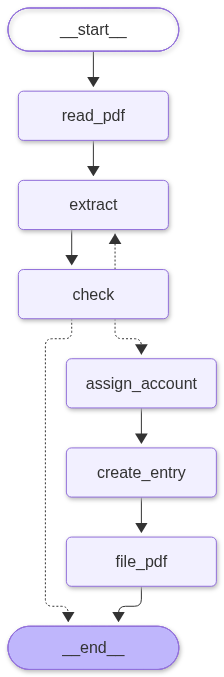

In [19]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

Alle drei Rechnungen durch den Graphen. `feedback` und `rounds` starten leer, damit
`extract` und `check` sie lesen können.

In LangSmith sieht man pro Rechnung jeden Knoten, und bei `check` das andere Modell.

In [20]:
for path in paths:
    result = graph.invoke({"path": path, "feedback": "", "rounds": 0})
    print(path, "| Runden:", result["rounds"])
    if result["approved"]:
        print("  Konto", result["account"], "—", result["reason"])
    else:
        print("  manuell prüfen:", result["feedback"])

data_invoices/rechnung_demo_clean.pdf | Runden: 1
  Konto 1510 — Der Massivholz-Esstisch und die gepolsterten Eichenstühle sind langlebige Einrichtungen, die über mehrere Jahre genutzt werden und daher aktiviert werden.


data_invoices/rechnung_test.pdf | Runden: 1
  Konto 6500 — Die Rechnung betrifft Fachbücher, Magazine, Lehrwerke und E-Books und gehört daher zu Büromaterial und Fachliteratur.


data_invoices/rechnung_uebung.pdf | Runden: 1
  Konto 6570 — Die Rechnung betrifft Cloud-Hosting, Daten-Backup, IT-Support, SSL-Zertifikat und Domain-Verwaltung und gehört daher zum Informatikaufwand.


Das Kreditorenjournal und die Ablage:

In [21]:
for entry in ledger:
    print(entry)

print(sorted(glob.glob("ablage/*/*.pdf")))

{'creditor': 'Hofer & Partner Schreinerei GmbH', 'invoice_number': '2026-0142', 'invoice_date': '2026-04-15', 'due_date': '2026-05-15', 'amount': 6723.5, 'currency': 'EUR', 'iban': 'DE89370400440532013000', 'account': '1510', 'status': 'offen'}
{'creditor': 'Alpenmedia Verlag GmbH', 'invoice_number': 'INV/2026/9912', 'invoice_date': '2026-04-23', 'due_date': '2026-05-23', 'amount': 1646.92, 'currency': 'EUR', 'iban': 'DE96100500000345678901', 'account': '6500', 'status': 'offen'}
{'creditor': 'Nordlicht Cloud Services UG', 'invoice_number': 'NL-2026-04-0087', 'invoice_date': '2026-04-03', 'due_date': '2026-04-17', 'amount': 1289.96, 'currency': 'EUR', 'iban': 'DE21200505501234567890', 'account': '6570', 'status': 'offen'}
['ablage/1510/2026-04-15_Hofer & Partner Schreinerei GmbH_2026-0142.pdf', 'ablage/6500/2026-04-23_Alpenmedia Verlag GmbH_INV-2026-9912.pdf', 'ablage/6570/2026-04-03_Nordlicht Cloud Services UG_NL-2026-04-0087.pdf']


**Vereinfachungen:**
- Jede Rechnung, die zweimal durchläuft, steht zweimal im Journal. Eine echte
  Buchhaltung prüft auf Duplikate.
- Die Rechnungen sind an verschiedene Empfänger adressiert. In Wirklichkeit gingen alle
  an dieselbe Firma.

### Für euer Projekt

- **Rollen:** Welche Schritte eures Agenten wären eine eigene Rolle mit eigenem Prompt,
  und welche sind fester Code? Begründet eure Entscheidung.

## Baustein zum Mitnehmen

In [22]:
import base64, shutil
from datetime import date, timedelta
from pathlib import Path
from typing import Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from pypdf import PdfReader
from langchain.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

REVIEW_MODEL = "azure_ai/mistral-large-3"
MAX_ROUNDS = 2

ACCOUNTS = {
    "1510": "Mobiliar und Einrichtungen: Möbel und Einrichtung, die mehrere Jahre genutzt werden (wird aktiviert)",
    "4400": "Einkauf Dienstleistungen: Fremdleistungen, die direkt in Kundenprojekte fliessen",
    "6100": "Unterhalt und Reparaturen: Reparatur und Wartung von Einrichtung und Geräten",
    "6500": "Büromaterial und Fachliteratur: Bücher, Zeitschriften, Abonnemente",
    "6570": "Informatikaufwand: Software, Cloud, Hosting, IT-Support, Domains",
    "6600": "Werbeaufwand: Inserate, Drucksachen, Messen",
}

EXTRACT_PROMPT = "Lies die Felder aus der Rechnung aus. Übernimm nur, was auf der Rechnung steht."

CHECK_PROMPT = """Du prüfst nach dem Vier-Augen-Prinzip, ob eine Extraktion zur Rechnung passt.
Die Extraktion hat genau diese Felder:
- invoice_number, supplier (nur Firmenname), invoice_date (JJJJ-MM-TT), currency, iban
- amount: zu zahlender Gesamtbetrag inkl. MwSt.
- description: ein Satz, was verrechnet wird
- payment_terms und payment_days: Zahlungsbedingungen und Frist in Tagen
Prüfe nur, ob die Werte dieser Felder stimmen. Weitere Angaben der Rechnung werden nicht gebraucht.
Das Format ist egal (Datum, Leerzeichen in der IBAN). Namen und Nummern vergleichst du Zeichen für Zeichen, auch Umlaute.
description ist richtig, wenn der Satz den Inhalt grob trifft.
Ist alles richtig, setze approved auf true und lass feedback leer."""

ACCOUNT_PROMPT = "Du kontierst Kreditorenrechnungen. Wähle das passende Konto aus dem Kontenplan."


class Invoice(BaseModel):
    invoice_number: str = Field(description="Rechnungsnummer")
    supplier: str = Field(description="nur der Firmenname des Rechnungsstellers")
    invoice_date: str = Field(description="Rechnungsdatum im Format JJJJ-MM-TT")
    description: str = Field(description="was verrechnet wird, in einem Satz")
    amount: float = Field(description="zu zahlender Gesamtbetrag inkl. MwSt.")
    currency: str = Field(description="Währung, z. B. EUR oder CHF")
    iban: str = Field(description="IBAN ohne Leerzeichen")
    payment_terms: str = Field(description="Zahlungsbedingungen, wie sie auf der Rechnung stehen")
    payment_days: int = Field(description="Zahlungsfrist in Tagen")


class Review(BaseModel):
    approved: bool = Field(description="True, wenn alle Felder stimmen")
    feedback: str = Field(description="welche Felder falsch sind und was richtig wäre, sonst leer")


class Assignment(BaseModel):
    reason: str = Field(description="Begründung in einem Satz")
    account: Literal[tuple(ACCOUNTS)] = Field(description="Kontonummer aus dem Kontenplan")


class InvoiceState(TypedDict):
    path: str
    text: str
    invoice: Invoice
    approved: bool
    feedback: str
    rounds: int
    account: str
    reason: str
    entry: dict


review_llm = ChatOpenAI(model=REVIEW_MODEL, base_url=LLM_BASE_URL,
                        api_key=os.environ["LITELLM_API_KEY"], temperature=0)
extractor = llm.with_structured_output(Invoice, method="json_schema")
reviewer = review_llm.with_structured_output(Review, method="json_schema")
accountant = llm.with_structured_output(Assignment, method="json_schema")
ledger = []


def read_pdf(state: InvoiceState):
    return {"text": "\n".join(page.extract_text() for page in PdfReader(state["path"]).pages)}


def extract(state: InvoiceState):
    with open(state["path"], "rb") as f:
        pdf = base64.b64encode(f.read()).decode()
    prompt = EXTRACT_PROMPT
    if state["feedback"]:
        prompt += f"\n\nDie Prüfung hat beanstandet:\n{state['feedback']}"
    message = HumanMessage(content=[
        {"type": "text", "text": prompt},
        {"type": "file", "file": {"filename": "rechnung.pdf",
                                  "file_data": "data:application/pdf;base64," + pdf}},
    ])
    return {"invoice": extractor.invoke([message])}


def check(state: InvoiceState):
    prompt = (f"{CHECK_PROMPT}\n\nRechnung:\n{state['text']}"
              f"\n\nExtraktion:\n{state['invoice'].model_dump_json(indent=1)}")
    result = reviewer.invoke(prompt)
    return {"approved": result.approved, "feedback": result.feedback, "rounds": state["rounds"] + 1}


def route_after_check(state: InvoiceState):
    if state["approved"]:
        return "assign_account"
    if state["rounds"] < MAX_ROUNDS:
        return "extract"
    return END


def assign_account(state: InvoiceState):
    chart = "\n".join(f"{number}: {description}" for number, description in ACCOUNTS.items())
    prompt = (f"{ACCOUNT_PROMPT}\n\nKontenplan:\n{chart}"
              f"\n\nRechnung:\n{state['invoice'].model_dump_json(indent=1)}")
    result = accountant.invoke(prompt)
    return {"account": result.account, "reason": result.reason}


def create_entry(state: InvoiceState):
    invoice = state["invoice"]
    due = date.fromisoformat(invoice.invoice_date) + timedelta(days=invoice.payment_days)
    entry = {"creditor": invoice.supplier, "invoice_number": invoice.invoice_number,
             "invoice_date": invoice.invoice_date, "due_date": due.isoformat(),
             "amount": invoice.amount, "currency": invoice.currency, "iban": invoice.iban,
             "account": state["account"], "status": "offen"}
    ledger.append(entry)
    return {"entry": entry}


def file_pdf(state: InvoiceState):
    invoice = state["invoice"]
    folder = Path("ablage") / state["account"]
    folder.mkdir(parents=True, exist_ok=True)
    name = f"{invoice.invoice_date}_{invoice.supplier}_{invoice.invoice_number}".replace("/", "-")
    shutil.copy(state["path"], folder / f"{name}.pdf")
    return {}


def build_graph():
    builder = StateGraph(InvoiceState)
    builder.add_node("read_pdf", read_pdf)
    builder.add_node("extract", extract)
    builder.add_node("check", check)
    builder.add_node("assign_account", assign_account)
    builder.add_node("create_entry", create_entry)
    builder.add_node("file_pdf", file_pdf)
    builder.add_edge(START, "read_pdf")
    builder.add_edge("read_pdf", "extract")
    builder.add_edge("extract", "check")
    builder.add_conditional_edges("check", route_after_check, ["assign_account", "extract", END])
    builder.add_edge("assign_account", "create_entry")
    builder.add_edge("create_entry", "file_pdf")
    builder.add_edge("file_pdf", END)
    return builder.compile()


graph = build_graph()